In [6]:
import os, gzip, struct, zipfile, glob
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from torchvision.utils import make_grid
from scipy.linalg import sqrtm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42); np.random.seed(42)
print('Using device:', device)

Using device: cpu


In [2]:
import os
import gzip
import struct
import zipfile
import glob
import numpy as np
import pandas as pd
import torch

USE_UPLOAD = True

def read_idx(path):
    op = gzip.open if path.endswith('.gz') else open
    with op(path, 'rb') as f:
        magic, = struct.unpack('>I', f.read(4))
        ndim = magic & 0xFF
        shape = struct.unpack('>' + 'I' * ndim, f.read(4 * ndim))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(shape)

def collect_files(paths):
    out = []
    for p in paths:
        if p.lower().endswith('.zip'):
            folder = p[:-4] + '_unzipped'
            with zipfile.ZipFile(p) as z: z.extractall(folder)
            out += [f for f in glob.glob(folder + '/**/*', recursive=True) if os.path.isfile(f)]
        else:
            out.append(p)
    return sorted(out)

def load_uploaded(paths):
    Xs, ys, idx_imgs, idx_lbls = [], [], [], []
    for p in collect_files(paths):
        n = os.path.basename(p).lower()
        if n.endswith('.csv'):
            df = pd.read_csv(p)
            if df.shape[1] == 785:
                ys.append(df.iloc[:, 0].values); Xs.append(df.iloc[:, 1:].values.reshape(-1, 28, 28))
            elif df.shape[1] == 784:
                Xs.append(df.values.reshape(-1, 28, 28))
        elif n.endswith('.npz'):
            d = np.load(p)
            for k in ('x_train', 'x_test'):
                if k in d: Xs.append(d[k])
            for k in ('y_train', 'y_test'):
                if k in d: ys.append(d[k])
        elif 'images' in n or 'idx3' in n:
            idx_imgs.append(read_idx(p))
        elif 'labels' in n or 'idx1' in n:
            idx_lbls.append(read_idx(p))
    if idx_imgs: Xs += idx_imgs
    if idx_lbls: ys += idx_lbls
    if not Xs: raise ValueError('Could not find MNIST images in the uploaded files.')
    X = np.concatenate(Xs).astype(np.float32)
    y = np.concatenate(ys).astype(np.int64) if ys else None
    return X, y

if USE_UPLOAD:
    from google.colab import files
    uploaded = files.upload()
    X, y = load_uploaded(list(uploaded.keys()))
else:
    from torchvision import datasets
    ds = datasets.MNIST('./data', train=True, download=True)
    X, y = ds.data.numpy().astype(np.float32), ds.targets.numpy()

assert y is not None, 'Labels are needed for the evaluation metrics (classifier-based).'
X = X / 255.0                                  # [0,1]
X = torch.tensor(X).unsqueeze(1)               # (N,1,28,28)
y = torch.tensor(y)
print('Dataset:', X.shape, 'labels:', y.shape, 'pixel range:', X.min().item(), X.max().item())

# 90% for GAN / classifier training, 10% held-out for testing
perm = torch.randperm(len(X))
n_test = len(X) // 10
test_idx, train_idx = perm[:n_test], perm[n_test:]
X_train, y_train = X[train_idx], y[train_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]

Saving archive.zip to archive (1).zip
Dataset: torch.Size([140000, 1, 28, 28]) labels: torch.Size([140000]) pixel range: 0.0 1.0


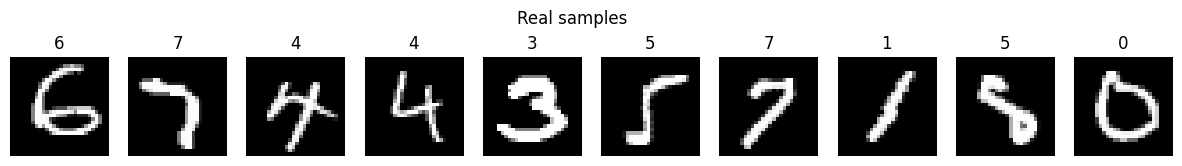

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    ax[i].imshow(X_train[i, 0], cmap='gray'); ax[i].set_title(int(y_train[i])); ax[i].axis('off')
plt.suptitle('Real samples'); plt.show()

In [6]:
## 2. Generator and Discriminator (DCGAN)
import torch
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

LATENT = 100
BATCH = 128
EPOCHS = 30
LR = 2e-4

class Generator(nn.Module):
    def __init__(self, z=LATENT):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(z, 128 * 7 * 7), nn.BatchNorm1d(128 * 7 * 7), nn.ReLU(True))
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),   # 14x14
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())                              # 28x28
    def forward(self, z):
        return self.net(self.fc(z).view(-1, 128, 7, 7))

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2, True),                         # 14x14
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),  # 7x7
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(128 * 7 * 7, 1))
    def forward(self, x):
        return self.net(x)          # raw logit

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None: nn.init.zeros_(m.bias)

G, D = Generator().to(device), Discriminator().to(device)
G.apply(init_weights); D.apply(init_weights)
print(G); print(D)

Generator(
  (fc): Sequential(
    (0): Linear(in_features=100, out_features=6272, bias=True)
    (1): BatchNorm1d(6272, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (net): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): Tanh()
  )
)
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Flatten(start_dim=1, end_dim=-1)
    (6): Dropout(p=0.3, inplace

In [8]:
## 3. Train the GAN
from torch.utils.data import DataLoader, TensorDataset
import torch
import torch.nn as nn

loader = DataLoader(TensorDataset(X_train * 2 - 1), batch_size=BATCH, shuffle=True, drop_last=True)  # scale to [-1,1]
optG = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
optD = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
fixed_z = torch.randn(64, LATENT, device=device)
lossG_hist, lossD_hist, snapshots = [], [], {}

for epoch in range(1, EPOCHS + 1):
    G.train(); D.train()
    lg, ld = 0, 0
    for (real,) in loader:
        real = real.to(device); b = real.size(0)
        # ---- train Discriminator (one-sided label smoothing) ----
        z = torch.randn(b, LATENT, device=device)
        fake = G(z).detach()
        lossD = bce(D(real), torch.full((b, 1), 0.9, device=device)) + bce(D(fake), torch.zeros(b, 1, device=device))
        optD.zero_grad(); lossD.backward(); optD.step()
        # ---- train Generator ----
        z = torch.randn(b, LATENT, device=device)
        lossG = bce(D(G(z)), torch.ones(b, 1, device=device))
        optG.zero_grad(); lossG.backward(); optG.step()
        lg += lossG.item(); ld += lossD.item()
    lossG_hist.append(lg / len(loader)); lossD_hist.append(ld / len(loader))
    print(f'Epoch {epoch:02d}/{EPOCHS} | D loss {lossD_hist[-1]:.3f} | G loss {lossG_hist[-1]:.3f}')
    if epoch in (1, 5, 10, 20, EPOCHS):
        G.eval()
        with torch.no_grad(): snapshots[epoch] = G(fixed_z).cpu()

torch.save(G.state_dict(), 'generator.pth'); torch.save(D.state_dict(), 'discriminator.pth')

Epoch 01/30 | D loss 0.725 | G loss 2.413
Epoch 02/30 | D loss 0.896 | G loss 1.915
Epoch 03/30 | D loss 0.956 | G loss 1.773
Epoch 04/30 | D loss 0.978 | G loss 1.734
Epoch 05/30 | D loss 0.956 | G loss 1.773
Epoch 06/30 | D loss 0.975 | G loss 1.758
Epoch 07/30 | D loss 0.971 | G loss 1.779
Epoch 08/30 | D loss 0.942 | G loss 1.829
Epoch 09/30 | D loss 0.944 | G loss 1.867
Epoch 10/30 | D loss 0.950 | G loss 1.858
Epoch 11/30 | D loss 0.920 | G loss 1.908
Epoch 12/30 | D loss 0.923 | G loss 1.925
Epoch 13/30 | D loss 0.934 | G loss 1.930
Epoch 14/30 | D loss 0.910 | G loss 1.942
Epoch 15/30 | D loss 0.918 | G loss 1.961
Epoch 16/30 | D loss 0.909 | G loss 1.974
Epoch 17/30 | D loss 0.901 | G loss 1.981
Epoch 18/30 | D loss 0.911 | G loss 1.973
Epoch 19/30 | D loss 0.914 | G loss 1.968
Epoch 20/30 | D loss 0.934 | G loss 1.942
Epoch 21/30 | D loss 0.915 | G loss 1.955
Epoch 22/30 | D loss 0.924 | G loss 1.943
Epoch 23/30 | D loss 0.924 | G loss 1.932
Epoch 24/30 | D loss 0.923 | G los

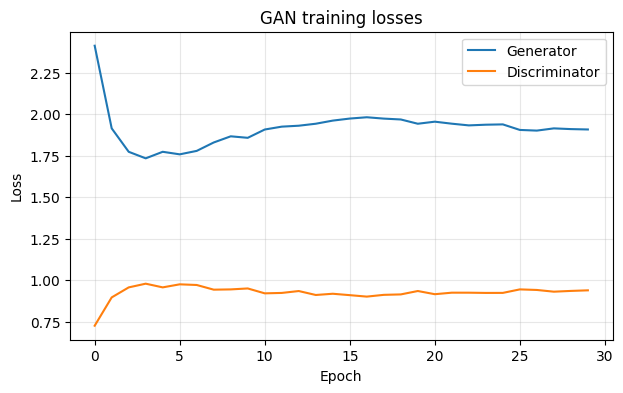

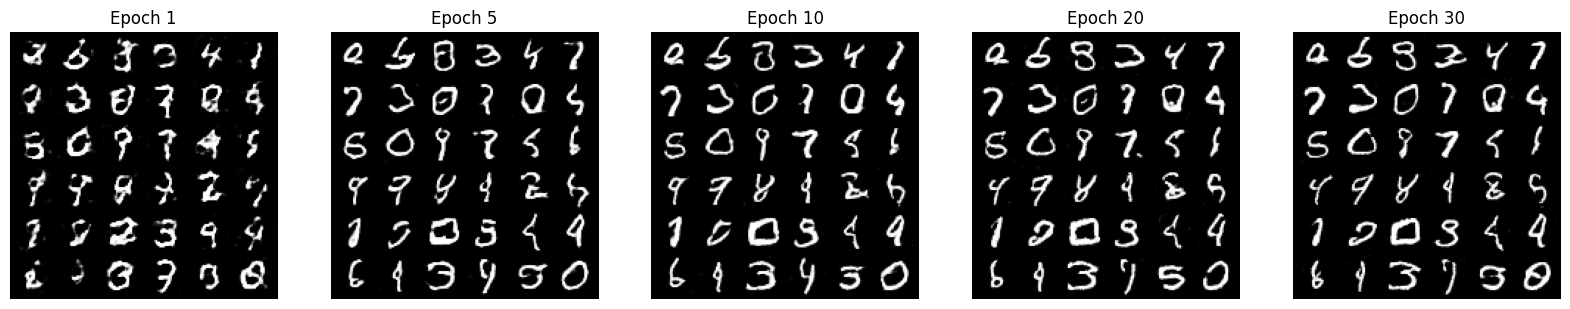

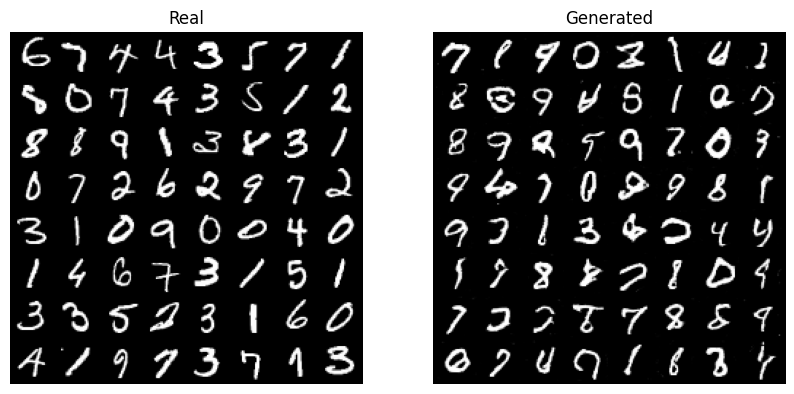

In [10]:
## 4. Visual analysis
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
import torch

# Loss curves
plt.figure(figsize=(7, 4))
plt.plot(lossG_hist, label='Generator'); plt.plot(lossD_hist, label='Discriminator')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('GAN training losses'); plt.legend(); plt.grid(alpha=.3); plt.show()

# Progress of the same latent vectors across epochs
fig, axs = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 4))
for ax, (ep, imgs) in zip(axs, snapshots.items()):
    ax.imshow(make_grid(imgs[:36], nrow=6, normalize=True, value_range=(-1, 1)).permute(1, 2, 0)[..., 0], cmap='gray')
    ax.set_title(f'Epoch {ep}'); ax.axis('off')
plt.show()

# Real vs generated side by side
@torch.no_grad()
def generate(n):
    G.eval(); out = []
    for i in range(0, n, 1000):
        out.append(G(torch.randn(min(1000, n - i), LATENT, device=device)).cpu())
    return torch.cat(out)

fake_vis = generate(64)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(make_grid(X_train[:64], nrow=8, padding=2).permute(1, 2, 0)[..., 0], cmap='gray'); ax[0].set_title('Real'); ax[0].axis('off')
ax[1].imshow(make_grid((fake_vis + 1) / 2, nrow=8, padding=2).permute(1, 2, 0)[..., 0], cmap='gray'); ax[1].set_title('Generated'); ax[1].axis('off')
plt.show()

## 5. Quantitative evaluation
Standard FID/IS use ImageNet-Inception, which is not suited to 28×28 digits. So a small CNN is trained on the real MNIST training split and used as the feature extractor / classifier:
- **FID** – distance between real and generated feature distributions (lower = better)
- **Inception Score (IS)** – quality + class diversity (max 10 for MNIST)
- **Class distribution** – checks for mode collapse
- **Pairwise distance** – diversity of generated vs real images
- **Nearest-neighbour distance** – novelty (are samples copies of training images?)

In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                  nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(),
                                  nn.Linear(64 * 7 * 7, 128), nn.ReLU())
        self.out = nn.Linear(128, 10)
    def forward(self, x, feats=False):
        f = self.conv(x)
        return (self.out(f), f) if feats else self.out(f)

def train_classifier(Xtr, ytr, epochs=5):
    m = CNN().to(device); opt = torch.optim.Adam(m.parameters(), 1e-3)
    dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=128, shuffle=True)
    for _ in range(epochs):
        m.train()
        for xb, yb in dl:
            xb, yb = xb.to(device) * 2 - 1, yb.to(device)
            loss = F.cross_entropy(m(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

@torch.no_grad()
def predict(m, imgs):            # imgs in [-1,1]
    logits, feats = [], []
    for i in range(0, len(imgs), 1000):
        l, f = m(imgs[i:i + 1000].to(device), feats=True)
        logits.append(l.cpu()); feats.append(f.cpu())
    return torch.cat(logits), torch.cat(feats)

def accuracy(m, Xe, ye):
    return (predict(m, Xe * 2 - 1)[0].argmax(1) == ye).float().mean().item()

clf = train_classifier(X_train, y_train)
print(f'Evaluation classifier test accuracy: {accuracy(clf, X_test, y_test):.4f}')

Evaluation classifier test accuracy: 0.9961


/tmp/ipykernel_2952/379408449.py:17: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = sqrtm(s1 @ s2)


FID  (generated vs real)       : 87.686   [real-vs-real baseline: 5.459]
Inception Score (generated)    : 8.360 ± 0.084   [real data: 9.832, max 10]
Mean pairwise L2 (generated)   : 20.208   [real: 20.247]
Mean nearest-real L2 (generated): 11.009   [real-vs-real: 7.717]


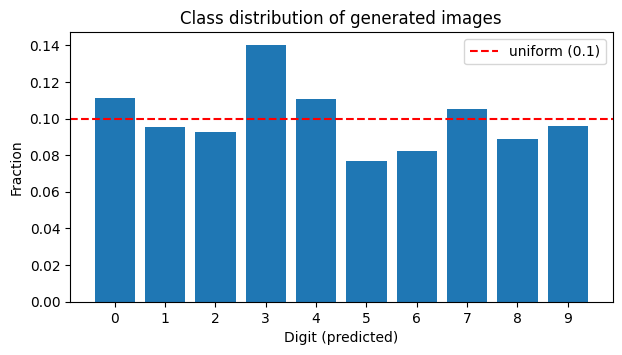

Mean classifier confidence on generated images: 0.936


In [14]:
from scipy.linalg import sqrtm
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

N_EVAL = 10000
fake = generate(N_EVAL)                                   # [-1,1]
real = X_train[:N_EVAL] * 2 - 1
lg_f, ft_f = predict(clf, fake); lg_r, ft_r = predict(clf, real)

# FID
def fid(f1, f2):
    f1, f2 = f1.numpy().astype(np.float64), f2.numpy().astype(np.float64)
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean = sqrtm(s1 @ s2)
    if np.iscomplexobj(covmean): covmean = covmean.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean))

# Inception Score
def inception_score(logits, splits=10):
    p = F.softmax(logits, 1).numpy(); scores = []
    for part in np.array_split(p, splits):
        py = part.mean(0, keepdims=True)
        scores.append(np.exp((part * (np.log(part + 1e-12) - np.log(py + 1e-12))).sum(1).mean()))
    return float(np.mean(scores)), float(np.std(scores))

fid_gen  = fid(ft_r, ft_f)
fid_base = fid(ft_r[:N_EVAL // 2], ft_r[N_EVAL // 2:])    # real-vs-real baseline (floor)
is_gen, is_std = inception_score(lg_f); is_real, _ = inception_score(lg_r)

# Diversity: mean pairwise L2 distance on random pairs
def mean_pair_dist(imgs, n=5000):
    a = imgs[torch.randint(len(imgs), (n,))].flatten(1); b = imgs[torch.randint(len(imgs), (n,))].flatten(1)
    return (a - b).norm(dim=1).mean().item()

# Novelty: distance of each generated image to its nearest real training image
nn_d = torch.cdist(fake[:1000].flatten(1).to(device), (X_train[:20000] * 2 - 1).flatten(1).to(device)).min(1).values.cpu()
nn_real = torch.cdist(real[:1000].flatten(1).to(device), (X_train[20000:40000] * 2 - 1).flatten(1).to(device)).min(1).values.cpu()

print(f'FID  (generated vs real)       : {fid_gen:.3f}   [real-vs-real baseline: {fid_base:.3f}]')
print(f'Inception Score (generated)    : {is_gen:.3f} ± {is_std:.3f}   [real data: {is_real:.3f}, max 10]')
print(f'Mean pairwise L2 (generated)   : {mean_pair_dist(fake):.3f}   [real: {mean_pair_dist(real):.3f}]')
print(f'Mean nearest-real L2 (generated): {nn_d.mean():.3f}   [real-vs-real: {nn_real.mean():.3f}]')

# Class distribution of generated digits (mode-collapse check)
pred_cls = lg_f.argmax(1)
counts = torch.bincount(pred_cls, minlength=10).numpy()
plt.figure(figsize=(7, 3.5)); plt.bar(range(10), counts / counts.sum())
plt.axhline(0.1, color='r', ls='--', label='uniform (0.1)'); plt.xticks(range(10)); plt.xlabel('Digit (predicted)')
plt.ylabel('Fraction'); plt.title('Class distribution of generated images'); plt.legend(); plt.show()

conf = F.softmax(lg_f, 1).max(1).values
print(f'Mean classifier confidence on generated images: {conf.mean():.3f}')

## 6. Does the synthetic data help? (augmentation experiment)
A classifier is trained on a **small** real subset, then on the same subset **plus GAN images** (labelled by the evaluation classifier).
 Both are tested on the held-out real test split.

In [15]:
N_REAL = 1000
Xs, ys = X_train[:N_REAL], y_train[:N_REAL]
syn = generate(5000)
syn_lbl = predict(clf, syn)[0].argmax(1)
syn01 = (syn + 1) / 2                                     # back to [0,1]

accs = {'real only': [], 'real + GAN': []}
for seed in range(3):
    torch.manual_seed(seed)
    accs['real only'].append(accuracy(train_classifier(Xs, ys, epochs=10), X_test, y_test))
    accs['real + GAN'].append(accuracy(train_classifier(torch.cat([Xs, syn01]), torch.cat([ys, syn_lbl]), epochs=10), X_test, y_test))

for k, v in accs.items(): print(f'{k:12s}: {np.mean(v):.4f} ± {np.std(v):.4f}')

real only   : 0.9268 ± 0.0027
real + GAN  : 0.9656 ± 0.0013


## 7. Summary / how to read the results
- **Visual**: generated digits should be sharp and legible, and improve from noise (epoch 1) to clean digits (epoch 30).
- **FID** close to the real-vs-real baseline → generated distribution matches the real one.
- **IS** close to the real-data IS (≈ 9.5+) → images are recognisable and classes are varied.
- **Class histogram near 0.1 each** → no mode collapse; **pairwise L2** similar to real → diversity preserved.
- **Nearest-neighbour distance** not near 0 → images are new, not memorised copies.
- **Augmentation test**: higher accuracy for "real + GAN" shows the synthetic images are useful for augmentation.